In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pd.set_option('display.max_columns',None)

In [3]:
df = pd.read_csv('Final_outlier_treated_data.csv')

In [4]:
df.head()

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,area_room_ratio
0,0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up a...,2,2,2,5.0,NaN,Relatively New,567.0,556.0,500.0,0,0,0,0,0,0,30,6,250.000000
1,1,flat,the lions cghs,sector 56,2.05,8542.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,8.0,West,Moderately Old,NaN,NaN,2400.0,0,0,0,0,0,0,49,47,600.000000
2,2,flat,dlf new town heights,sector 90,1.25,6477.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up ...,3,3,3+,17.0,South-East,Relatively New,1930.0,1700.0,1500.0,1,0,1,0,0,0,65,6,643.333333
3,3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up...,3,3,3+,7.0,South,Old Property,2000.0,1900.0,1800.0,1,1,1,0,1,0,166,47,666.666667
4,4,flat,sare crescent parc,sector 92,0.66,4977.0,1326.0,Carpet area: 1326 (123.19 sq.m.),3,2,2,15.0,North,Relatively New,NaN,NaN,1326.0,0,0,0,0,0,1,44,8,442.000000


In [5]:
df.isnull().sum()

Unnamed: 0                 0
property_type              0
society                    1
sector                     0
price                      0
price_per_sqft             0
area                       0
areaWithType               0
bedRoom                    0
bathroom                   0
balcony                    0
floorNum                  16
facing                  1010
agePossession              0
super_built_up_area     1679
built_up_area           1970
carpet_area             1713
pooja_room                 0
study_room                 0
servant_room               0
store_room                 0
others                     0
furnishing_type            0
luxury_score               0
NearbyLocationsCount       0
area_room_ratio            0
dtype: int64

## built_up_area

<Axes: xlabel='built_up_area', ylabel='super_built_up_area'>

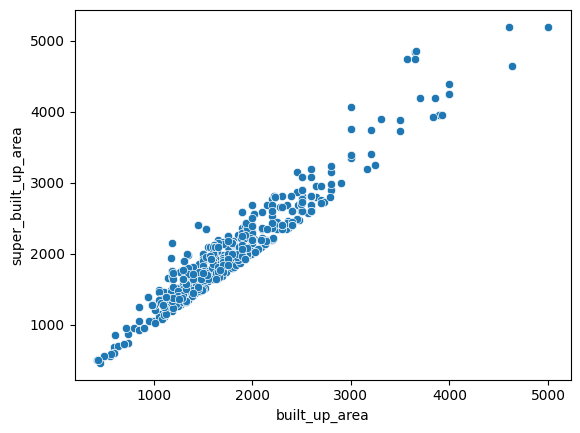

In [7]:
sns.scatterplot(x=df['built_up_area'],y=df['super_built_up_area'])

<Axes: xlabel='built_up_area', ylabel='carpet_area'>

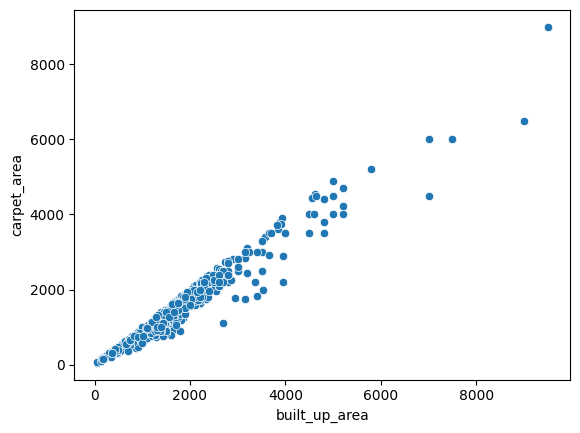

In [8]:
sns.scatterplot(x=df['built_up_area'],y=df['carpet_area'])

In [9]:
((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))

0       False
1       False
2       False
3       False
4       False
        ...  
3550    False
3551    False
3552    False
3553    False
3554    False
Length: 3555, dtype: bool

In [10]:
df.shape

(3555, 26)

In [11]:
all_present_df = df[~((df['super_built_up_area'].isnull()) | (df['built_up_area'].isnull()) | (df['carpet_area'].isnull()))]

In [12]:
all_present_df.shape

(531, 26)

In [13]:
super_to_built_up_ratio = (all_present_df['super_built_up_area']/all_present_df['built_up_area']).median()

In [14]:
carpet_to_built_up_ratio = (all_present_df['carpet_area']/all_present_df['built_up_area']).median()

In [15]:
print(super_to_built_up_ratio, carpet_to_built_up_ratio)

1.105263157894737 0.9


In [16]:
# both present built up null
sbc_df = df[~(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & ~(df['carpet_area'].isnull())]

In [17]:
sbc_df.head()

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,area_room_ratio
8,8,flat,ss the leaf,sector 85,1.150,10017.0,1148.0,Super Built up area 1640(152.36 sq.m.)Carpet a...,2,2,3+,18.0,East,Relatively New,1640.0,NaN,1148.0,0,0,0,1,0,0,156,13,574.000000
15,15,flat,eldeco accolade,sohna road,0.715,4907.0,1457.0,Super Built up area 1457(135.36 sq.m.)Carpet a...,2,2,3+,10.0,North-East,Relatively New,1457.0,NaN,849.0,0,1,0,0,0,0,49,7,728.500000
17,17,flat,umang monsoon breeze,sector 78,1.200,6494.0,1848.0,Super Built up area 2250(209.03 sq.m.)Carpet a...,3,3,2,8.0,NaN,Moderately Old,2250.0,NaN,1848.0,1,0,0,0,0,1,8,7,616.000000
22,22,flat,tulip violet,sector 69,1.500,10714.0,1400.0,Super Built up area 1578(146.6 sq.m.)Carpet ar...,3,3,2,8.0,North-East,Relatively New,1578.0,NaN,1400.0,1,0,0,0,0,0,174,10,466.666667
24,24,flat,hero homes,sector 104,1.900,11249.0,1689.0,Super Built up area 1689(156.91 sq.m.)Carpet a...,3,3,3,16.0,NaN,Undefined,1689.0,NaN,1082.0,1,0,0,0,0,0,103,7,563.000000


In [18]:
sbc_df.shape

(421, 26)

In [19]:
sbc_df['built_up_area'].fillna(round(((sbc_df['super_built_up_area']/1.105) + (sbc_df['carpet_area']/0.9))/2),inplace=True)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_21584\1215074969.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sbc_df['built_up_area'].fillna(round(((sbc_df['super_built_up_area']/1.105) + (sbc_df['carpet_area']/0.9))/2),inplace=True)
C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_21584\1215074969.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-

In [20]:
df.update(sbc_df)

In [21]:
df.isnull().sum()

Unnamed: 0                 0
property_type              0
society                    1
sector                     0
price                      0
price_per_sqft             0
area                       0
areaWithType               0
bedRoom                    0
bathroom                   0
balcony                    0
floorNum                  16
facing                  1010
agePossession              0
super_built_up_area     1679
built_up_area           1549
carpet_area             1713
pooja_room                 0
study_room                 0
servant_room               0
store_room                 0
others                     0
furnishing_type            0
luxury_score               0
NearbyLocationsCount       0
area_room_ratio            0
dtype: int64

In [22]:
# sb present c is null built up null
sb_df = df[~(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull())]
sb_df.head()

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,area_room_ratio
5,5,flat,godrej oasis,sector 88a,1.50,8108.0,1850.0,Super Built up area 1850(171.87 sq.m.),3,3,3+,11.0,North-East,New Property,1850.0,NaN,NaN,0,0,0,0,0,0,39,7,616.666667
6,6,flat,bestech park view spa next,sector 67,2.70,11489.0,2350.0,Super Built up area 2350(218.32 sq.m.),4,4,3+,9.0,South-West,Moderately Old,2350.0,NaN,NaN,1,0,1,0,0,0,149,12,587.500000
12,12,flat,bptp terra,sector 37d,1.78,8124.0,2191.0,Super Built up area 2191(203.55 sq.m.),4,3,3,10.0,East,Relatively New,2191.0,NaN,NaN,0,0,1,0,0,0,127,11,547.750000
13,13,flat,dlf express greens,manesar,1.20,6504.0,1845.0,Super Built up area 1845(171.41 sq.m.),3,4,2,5.0,East,Relatively New,1845.0,NaN,NaN,0,0,1,0,1,0,43,11,615.000000
14,14,flat,dlf the skycourt,sector 86,1.35,6998.0,1929.0,Super Built up area 1929(179.21 sq.m.),3,3,1,9.0,North-West,Relatively New,1929.0,NaN,NaN,0,0,0,0,0,0,119,10,643.000000


In [23]:
sb_df['built_up_area'].fillna(round(sb_df['super_built_up_area']/1.105),inplace=True)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_21584\1714170073.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sb_df['built_up_area'].fillna(round(sb_df['super_built_up_area']/1.105),inplace=True)
C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_21584\1714170073.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sb_df['built_up_a

In [24]:
df.update(sb_df)

In [25]:
df.isnull().sum()

Unnamed: 0                 0
property_type              0
society                    1
sector                     0
price                      0
price_per_sqft             0
area                       0
areaWithType               0
bedRoom                    0
bathroom                   0
balcony                    0
floorNum                  16
facing                  1010
agePossession              0
super_built_up_area     1679
built_up_area            673
carpet_area             1713
pooja_room                 0
study_room                 0
servant_room               0
store_room                 0
others                     0
furnishing_type            0
luxury_score               0
NearbyLocationsCount       0
area_room_ratio            0
dtype: int64

In [26]:
# sb null c is present built up null
c_df = df[(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & ~(df['carpet_area'].isnull())]

In [27]:
c_df.head()

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,area_room_ratio
1,1,flat,the lions cghs,sector 56,2.05,8542.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,8.0,West,Moderately Old,NaN,NaN,2400.0,0,0,0,0,0,0,49,47,600.0
4,4,flat,sare crescent parc,sector 92,0.66,4977.0,1326.0,Carpet area: 1326 (123.19 sq.m.),3,2,2,15.0,North,Relatively New,NaN,NaN,1326.0,0,0,0,0,0,1,44,8,442.0
19,19,flat,siddhartha apartment,sector 95,1.10,4327.0,2542.0,Carpet area: 2542 (236.16 sq.m.),4,3,3,9.0,North,Relatively New,NaN,NaN,2542.0,0,0,1,0,1,0,22,5,635.5
28,28,flat,signature global park,sohna road,0.52,6326.0,822.0,Carpet area: 822 (76.37 sq.m.),2,2,2,3.0,North-West,Relatively New,NaN,NaN,822.0,1,0,0,0,0,0,161,8,411.0
32,32,flat,not applicable,sector 4,0.42,5600.0,750.0,Carpet area: 750 (69.68 sq.m.),2,2,1,3.0,NaN,Relatively New,NaN,NaN,750.0,0,0,0,0,0,0,26,49,375.0


In [28]:
c_df['built_up_area'].fillna(round(c_df['carpet_area']/0.9),inplace=True)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_21584\2136919732.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  c_df['built_up_area'].fillna(round(c_df['carpet_area']/0.9),inplace=True)
C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_21584\2136919732.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  c_df['built_up_area'].fillna(

In [29]:
df.update(c_df)

In [30]:
df.isnull().sum()

Unnamed: 0                 0
property_type              0
society                    1
sector                     0
price                      0
price_per_sqft             0
area                       0
areaWithType               0
bedRoom                    0
bathroom                   0
balcony                    0
floorNum                  16
facing                  1010
agePossession              0
super_built_up_area     1679
built_up_area              0
carpet_area             1713
pooja_room                 0
study_room                 0
servant_room               0
store_room                 0
others                     0
furnishing_type            0
luxury_score               0
NearbyLocationsCount       0
area_room_ratio            0
dtype: int64

<Axes: xlabel='built_up_area', ylabel='price'>

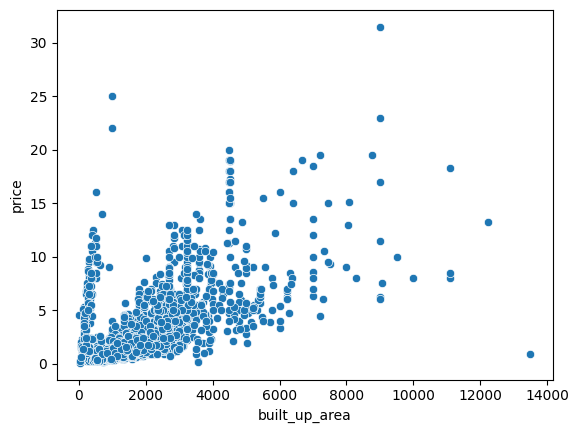

In [32]:
sns.scatterplot(x=df['built_up_area'],y=df['price'])

In [33]:
anamoly_df = df[(df['built_up_area'] < 2000) & (df['price'] > 2.5)][['price','area','built_up_area']]

In [35]:
anamoly_df.sample(5)

,price,area,built_up_area
3554,3.69,1557.0,1557.0
3208,2.55,1557.0,1557.0
2635,3.75,1467.0,163.0
111,3.60,1449.0,1449.0
3439,2.51,1696.0,1534.0


In [36]:
anamoly_df['built_up_area'] = anamoly_df['area']

In [37]:
df.update(anamoly_df)

<Axes: xlabel='built_up_area', ylabel='price'>

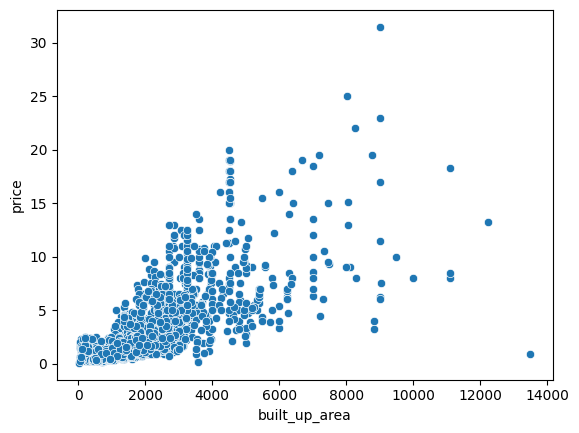

In [38]:
sns.scatterplot(x=df['built_up_area'],y=df['price'])

In [39]:
df.drop(columns=['area','areaWithType','super_built_up_area','carpet_area','area_room_ratio'],inplace=True)

In [40]:
df.head()

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,0,flat,gls arawali homes,sohna road,0.35,7000.0,2,2,2,5.0,NaN,Relatively New,556.0,0,0,0,0,0,0,30,6
1,1,flat,the lions cghs,sector 56,2.05,8542.0,4,4,3+,8.0,West,Moderately Old,2667.0,0,0,0,0,0,0,49,47
2,2,flat,dlf new town heights,sector 90,1.25,6477.0,3,3,3+,17.0,South-East,Relatively New,1700.0,1,0,1,0,0,0,65,6
3,3,flat,sagar apartment,sector 56,1.45,7250.0,3,3,3+,7.0,South,Old Property,1900.0,1,1,1,0,1,0,166,47
4,4,flat,sare crescent parc,sector 92,0.66,4977.0,3,2,2,15.0,North,Relatively New,1473.0,0,0,0,0,0,1,44,8


In [41]:
df.isnull().sum()

Unnamed: 0                 0
property_type              0
society                    1
sector                     0
price                      0
price_per_sqft             0
bedRoom                    0
bathroom                   0
balcony                    0
floorNum                  16
facing                  1010
agePossession              0
built_up_area              0
pooja_room                 0
study_room                 0
servant_room               0
store_room                 0
others                     0
furnishing_type            0
luxury_score               0
NearbyLocationsCount       0
dtype: int64

## floorNum

In [42]:
df[df['floorNum'].isnull()]

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
146,150,house,dlf new town heights,sector 86,2.47,7719.0,4,4,3+,NaN,West,Moderately Old,2800.0,1,0,1,0,0,0,130,15
164,169,house,independent,sector 25,13.00,45710.0,6,8,3+,NaN,NaN,Relatively New,2844.0,1,1,1,1,0,1,0,49
329,340,house,emaar mgf marbella,sector 66,9.00,21251.0,4,4,3+,NaN,South-West,Relatively New,5200.0,1,0,1,1,0,1,114,14
390,403,house,independent,sector 3,1.50,10288.0,3,3,0,NaN,NaN,Old Property,210.0,0,0,0,0,0,0,0,49
450,465,house,jacob pura,sector 12,0.35,9722.0,2,1,0,NaN,NaN,Old Property,360.0,0,0,0,0,0,0,0,0
998,1037,house,independent,sector 7,6.50,15046.0,3,2,3+,NaN,NaN,Old Property,4320.0,0,0,0,0,0,0,9,50
1075,1116,house,independent,sector 4,4.12,8889.0,2,1,3+,NaN,NaN,Moderately Old,4635.0,0,0,0,0,0,0,0,49
1204,1253,house,vipul tatvam villa,sector 48,8.50,26235.0,4,4,2,NaN,East,Moderately Old,3240.0,1,0,1,1,0,0,88,15
1323,1383,house,independent,sector 26,4.60,12198.0,4,4,3+,NaN,NaN,Old Property,3771.0,0,0,0,0,0,0,28,48
1686,1770,flat,experion heartsong,dwarka expressway,1.08,6150.0,3,3,0,NaN,NaN,Under Construction,1758.0,0,0,0,0,0,0,0,0


In [43]:
df[df['property_type'] == 'house']['floorNum'].median()

np.float64(2.0)

In [44]:
df['floorNum'].fillna(2.0,inplace=True)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_21584\15612474.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['floorNum'].fillna(2.0,inplace=True)


In [45]:
df.isnull().sum()

Unnamed: 0                 0
property_type              0
society                    1
sector                     0
price                      0
price_per_sqft             0
bedRoom                    0
bathroom                   0
balcony                    0
floorNum                   0
facing                  1010
agePossession              0
built_up_area              0
pooja_room                 0
study_room                 0
servant_room               0
store_room                 0
others                     0
furnishing_type            0
luxury_score               0
NearbyLocationsCount       0
dtype: int64

## facing

In [46]:
1010/df.shape[0]

0.2841068917018284

<Axes: ylabel='count'>

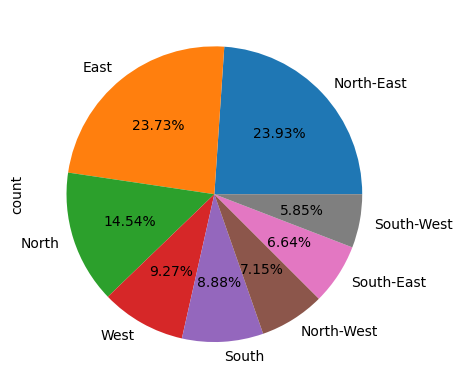

In [47]:
df['facing'].value_counts().plot(kind='pie',autopct='%0.2f%%')

In [48]:
df.drop(columns=['facing'],inplace=True)

In [49]:
df.sample(5)

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
717,741,flat,ild grand centra,sector 37c,0.95,5220.0,3,1,0,0.0,Undefined,1820.0,0,0,0,0,0,0,0,0
1000,1039,flat,vatika lifestyle homes,sector 83,1.05,7500.0,3,2,2,1.0,Moderately Old,1600.0,0,0,0,0,0,0,106,10
3519,3762,flat,deepak minda,manesar,1.20,4528.0,3,3,3+,6.0,Moderately Old,2944.0,0,0,1,0,0,0,7,11
1609,1687,flat,ansal heights 86,sector 86,1.30,4666.0,4,6,2,11.0,New Property,2521.0,0,0,1,0,1,0,86,4
1656,1736,flat,emaar palm gardens,sector 83,1.80,9474.0,3,4,0,9.0,Undefined,1900.0,0,0,0,0,0,0,55,11


In [50]:
df.isnull().sum()

Unnamed: 0              0
property_type           0
society                 1
sector                  0
price                   0
price_per_sqft          0
bedRoom                 0
bathroom                0
balcony                 0
floorNum                0
agePossession           0
built_up_area           0
pooja_room              0
study_room              0
servant_room            0
store_room              0
others                  0
furnishing_type         0
luxury_score            0
NearbyLocationsCount    0
dtype: int64

In [51]:
# 2935	3105	flat	NaN	sector 78	0.60	
df.drop(index=[2935],inplace=True)

In [52]:
df.isnull().sum()

Unnamed: 0              0
property_type           0
society                 0
sector                  0
price                   0
price_per_sqft          0
bedRoom                 0
bathroom                0
balcony                 0
floorNum                0
agePossession           0
built_up_area           0
pooja_room              0
study_room              0
servant_room            0
store_room              0
others                  0
furnishing_type         0
luxury_score            0
NearbyLocationsCount    0
dtype: int64

## agePossession 

In [53]:
df['agePossession'].value_counts()

agePossession
Relatively New        1604
New Property           557
Moderately Old         544
Undefined              432
Old Property           293
Under Construction     124
Name: count, dtype: int64

In [54]:
df[df['agePossession'] == 'Undefined']

,Unnamed: 0,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
24,24,flat,hero homes,sector 104,1.90,11249.0,3,3,3,16.0,Undefined,1365.0,1,0,0,0,0,0,103,7
48,48,house,independent,sector 43,5.75,23663.0,4,4,2,4.0,Undefined,2430.0,0,0,1,1,0,1,153,48
52,53,flat,m3m capital,sector 113,1.83,13969.0,2,2,0,7.0,Undefined,1310.0,0,0,0,0,0,0,68,8
65,66,flat,raheja revanta,sector 78,4.75,16886.0,3,3,2,31.0,Undefined,2813.0,0,0,1,0,0,0,100,10
87,88,house,independent,sector 7,0.69,9103.0,1,1,1,2.0,Undefined,758.0,0,0,0,0,0,0,0,48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3483,3722,flat,m3m heights,sector 65,2.86,13999.0,3,3,3,45.0,Undefined,2267.0,0,0,1,0,0,0,48,11
3492,3732,flat,godrej summit premia towers,sector 104,0.90,7149.0,2,2,0,16.0,Undefined,1259.0,0,0,0,0,0,0,0,47
3504,3746,flat,imperia the esfera,sector 37c,0.90,6272.0,3,3,3,9.0,Undefined,1435.0,0,0,0,0,0,0,66,8
3512,3754,flat,raheja sampada,sector 92,0.70,4453.0,3,3,0,7.0,Undefined,1572.0,0,0,0,0,0,0,0,14


In [55]:
def mode_based_imputation(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['sector'] == row['sector']) & (df['property_type'] == row['property_type'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0] 
        else:
            return np.nan
    else:
        return row['agePossession']

In [56]:
df['agePossession'] = df.apply(mode_based_imputation,axis=1)

In [57]:
df['agePossession'].value_counts()

agePossession
Relatively New        1786
New Property           635
Moderately Old         585
Old Property           331
Under Construction     126
Undefined               91
Name: count, dtype: int64

In [58]:
def mode_based_imputation2(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['sector'] == row['sector'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0] 
        else:
            return np.nan
    else:
        return row['agePossession']

In [59]:
df['agePossession'] = df.apply(mode_based_imputation2,axis=1)

In [60]:
df['agePossession'].value_counts()

agePossession
Relatively New        1804
New Property           658
Moderately Old         592
Old Property           342
Under Construction     126
Undefined               32
Name: count, dtype: int64

In [61]:
def mode_based_imputation3(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['property_type'] == row['property_type'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0] 
        else:
            return np.nan
    else:
        return row['agePossession']

In [62]:
df['agePossession'] = df.apply(mode_based_imputation3,axis=1)

In [63]:
df['agePossession'].value_counts()

agePossession
Relatively New        1818
New Property           658
Moderately Old         610
Old Property           342
Under Construction     126
Name: count, dtype: int64

In [64]:
df.isnull().sum()

Unnamed: 0              0
property_type           0
society                 0
sector                  0
price                   0
price_per_sqft          0
bedRoom                 0
bathroom                0
balcony                 0
floorNum                0
agePossession           0
built_up_area           0
pooja_room              0
study_room              0
servant_room            0
store_room              0
others                  0
furnishing_type         0
luxury_score            0
NearbyLocationsCount    0
dtype: int64

In [65]:
df.to_csv('missing_value_imputation_data.csv',index=False)

In [66]:
df.shape

(3554, 20)

In [69]:
df = df.drop(columns=['Unnamed: 0'])

In [70]:
df.shape

(3554, 19)

In [71]:
df.to_csv('missing_value_imputation_data.csv',index=False)